# Q1B | Display the Statistical Values

> *Display the statistical values for each of the attributes, along with visualizations (ex: histogram) of the distributions for each attribute. Explain noticeable traits for key attributes. Are there any attributes that might require special treatment? If so, what special treatment might they require?*

---

#### IMPORTANT

This notebook uses only the `train` dataset, so no analysis or treatment decision is influenced by the test data (`data snooping`).

# Answer Summary

**Statistics and visualizations:** each attribute below has a statistics table (center, spread, skew, kurtosis, IQR outliers, correlation with `Life Ladder`) and four plots (histogram w/ normal overlay, QQ plot, Life Ladder box plot below vs at or above the step threshold, and a scatter against Life Ladder with linear, LOWESS, step and hinge fits). The target, `Life Ladder`, has the same statistics table (without the correlation) and the histogram and QQ plot only.

**Noticeable traits**

- **The target, Life Ladder:** roughly symmetric, mesokurtic, with no outliers and no missing values.
- **Strength of the relationship with Life Ladder:**
  - **Strong:** Log GDP per capita, Healthy life expectancy at birth and Social support.
  - **Moderate:** Positive affect, Freedom to make life choices and Perceptions of corruption.
  - **Weak:** Negative affect and Generosity.
- **Most relationships are not straight lines.** In the scatter plots LOWESS bends away from the linear fit for every attribute except Positive affect.
- **A step alone is rarely enough.** The step R² is below the linear R² for six of the eight attributes. The exceptions are Perceptions of corruption and Generosity.
- **A hinge is a consistent improvement.** The hinge R² is above the linear R² for all eight attributes. The gain is clearest for Social support, Healthy life expectancy and Freedom, and small for the other five.
- **Values crowded against the top of the range:** Perceptions of corruption, Social support and Freedom all bunch just below 1 with a long tail toward low values. Their low outliers are part of the trend, not errors.
- **The attributes are on very different scales.** Healthy life expectancy has a std of 7.478, while six of the other seven are under 0.2.
- **Generosity** is centered on 0 and is the only attribute with negative values.

**Special treatment:** yes. Every attribute's `Notes / Observations` section below ends with a `Special Treatment` list of the treatments it might require, ranked by expected benefit. The target needs none.

---

# Imports

In [1]:
import pandas as pd
from IPython.display import display

from Q1.consts import *

from utils import (
	read_csv_to_df,
	STATISTICS,
	PLOTTING,
)

pd.set_option('display.max_rows', None)
pd.set_option('display.min_rows', None)
pd.set_option('display.max_columns', None)

# Fetch Data

In [2]:
train_df = read_csv_to_df(path=TRAIN_PATH)

# Statistical Values

## How to Read the Plots (applies to every attribute below)

- **Histogram w/ normal overlay:** the attribute's distribution against a normal curve with the same mean and SD. Gaps between the bars and the red curve show skew, values piling up at one end, or more than one peak.
- **QQ plot:** the sorted values against the values a normal distribution would produce. Points on the red line mean normal.
  - Low end below the line and high end above it: heavy tails. The reverse: light tails.
  - Points bowing above the line through the middle: left skew. Bowing below: right skew.
  - A flat run at one end: values piling up against a limit.
- **Box plot:** Life Ladder for the rows below vs at or above the step threshold. The further apart the boxes, the more a step alone explains.
- **Scatter plot fits:**
  - **Linear (red):** the straight line. This is the only shape a raw attribute can give a linear regression.
  - **LOWESS (green):** a smoothed local average that does not assume a shape. When it bends away from the red line, the relationship is not linear and the raw attribute will underfit.
  - **Step (blue, dotted):** one mean on each side of the step threshold. If its R² is close to the linear R², a step indicator (a 0 / 1 column that is 1 on one side of the step threshold) carries most of the signal.
  - **Hinge (violet, dashed):** two straight segments joined at the hinge threshold. If its R² beats the linear R², the attribute is a candidate for a hinge term (a column such as `max(0, x - threshold)`) or a spline term.
  - The step and hinge thresholds are searched on the same rows they are scored on, so their R² values are optimistic.

## Life Ladder (Target)

In [3]:
STATISTICS.statistics_df(series=train_df[TARGET])

,Life Ladder
count,1559.0
missing,0
% missing,0.0
mean,5.469
std,1.113
min,2.375
25%,4.65
50%,5.374
75%,6.272
max,8.019


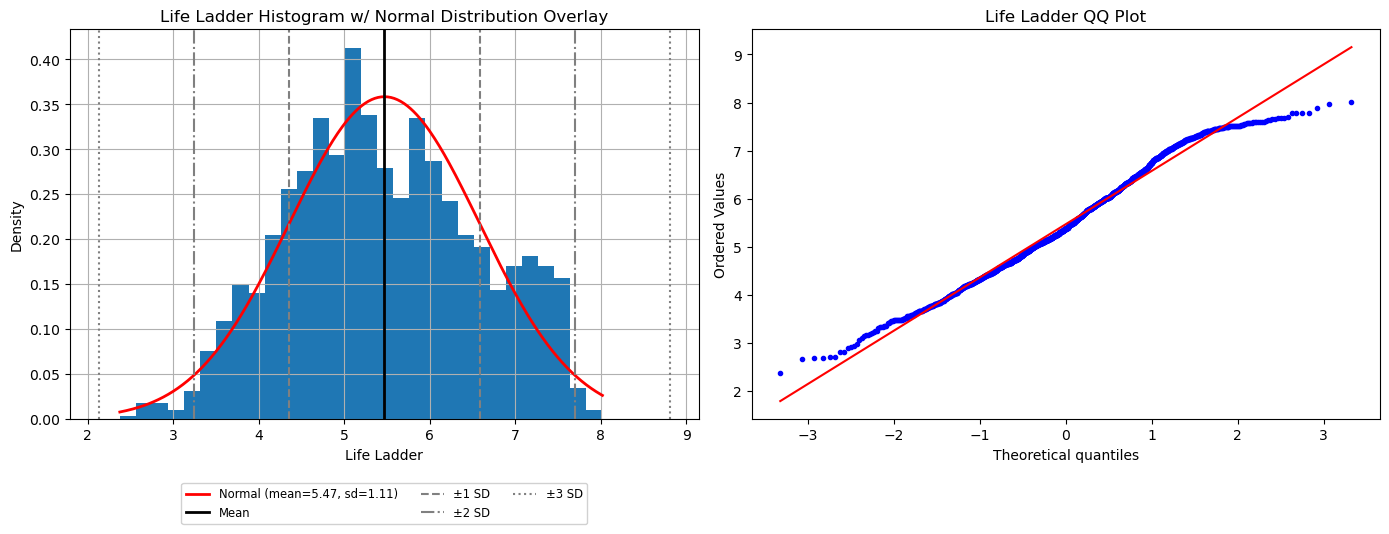

In [4]:
PLOTTING.distribution_plots(series=train_df[TARGET]);

### Notes / Observations

The target has no box plot or scatter plot, since those show an attribute against the target. Its table has no `corr with target` row for the same reason.

#### Noticeable Traits / Key Attributes

- **Roughly symmetric (skew 0.075) and mesokurtic (-0.67).** The mean (5.469) and median (5.374) are close, and half the values sit between the 25% and 75% values (4.65 and 6.272).
- **Complete and clean:** no missing values and no outliers on either side (fences 2.215 and 8.707), so no row has to be dropped or capped because of the target.
- **Histogram:** close to the normal curve, with the main peak near 5 and a smaller second bump around 7 to 7.5 that sits above the curve.
- **QQ plot:** on the line through the middle. The low end sits above the line and the high end below it (light tails), and the top flattens just below the max of 8.019.

#### Special Treatment

- **None needed.** There is no skew to fix, no outlier to handle and nothing to impute, so the target goes into the model as it is.

## Perceptions of Corruption

In [5]:
STATISTICS.statistics_df(series=train_df[COLUMNS['POC']['col']], target=train_df[TARGET])

,Perceptions of corruption
count,1473.0
missing,86
% missing,5.516
mean,0.748
std,0.187
min,0.035
25%,0.691
50%,0.804
75%,0.873
max,0.983


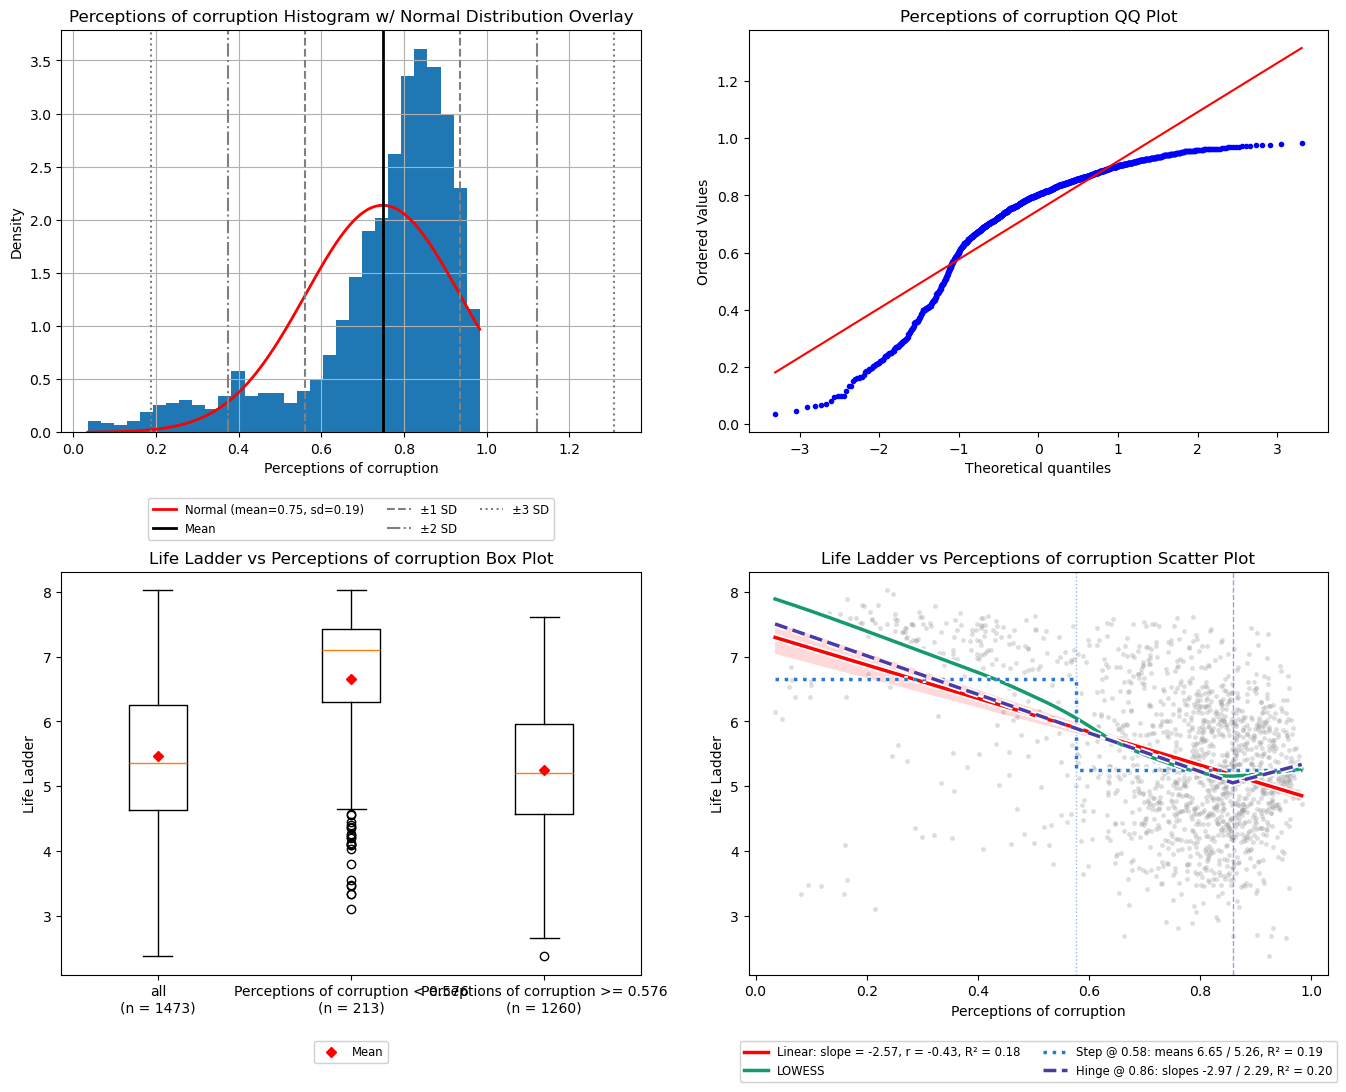

In [6]:
PLOTTING.single_feature_plots(df=train_df, feature=COLUMNS['POC']['col'], target=TARGET, threshold="auto");

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **Highly left skewed (-1.536) and leptokurtic (2.006).** Half the values sit between the 25% and 75% values (0.691 and 0.873), crowded just below the max of 0.983, with a long thin tail down to 0.035. The QQ plot shows both: the low end falls far below the line and the top flattens near 0.98.
- **130 low outliers** below the 0.418 fence, and none above.
- **Moderate negative relationship:** r = -0.428 (R² 0.18).
- **The signal is in the low tail, which is where the outliers are.** LOWESS falls steeply up to about 0.6 and is nearly flat from about 0.75 to 1. The step at 0.58 (means 6.65 / 5.26, R² 0.19) matches the straight line (R² 0.18) with a step alone. The box plot agrees: the 213 rows below 0.576 have a median Life Ladder of about 7.1, vs about 5.2 for the 1,260 rows at or above.
- **A straight line misfits both ends.** It sits below LOWESS in the low tail and keeps falling across the crowded top, where LOWESS is flat.
- **Most missing values of any attribute:** 86 (5.516%).

#### Special Treatment

Candidates, ranked by expected benefit:

1. **Raw value plus a step indicator** (1 when the value is below the step threshold of 0.58). The raw column keeps the slope and the step indicator adds the level shift the box plot shows.
2. **Raw value plus a hinge term:** `[x, max(0, x - 0.86)]` (R² 0.20). It lets the line flatten across the crowded top. The hinge turns upward there (slope 2.29) more sharply than LOWESS does, so part of that fit may be noise.
3. **Raw value alone.** The three fits are close (R² 0.18, 0.19, 0.20) and the step and hinge R² are optimistic, so expect a small gain at best.

- **Missing values:** if the rows are kept, fill with the median (0.804), not the mean (0.748), which the low tail pulls down. Both sit in the flat part of the curve, so the choice of fill value should matter little.
- **Avoid clipping, winsorizing or dropping the 130 low outliers.** They are the part of the range where Life Ladder changes.
- **Avoid replacing the raw value** with the step indicator alone or with a shape that is flat above 0.58. LOWESS is still falling between 0.58 and about 0.75.
- **Avoid skew fixing transforms** (ex Yeo-Johnson). They stretch the crowded top, where LOWESS is flat, and compress the tail that carries the signal.

## Social Support

In [7]:
STATISTICS.statistics_df(series=train_df[COLUMNS['SS']['col']], target=train_df[TARGET])

,Social support
count,1549.0
missing,10
% missing,0.641
mean,0.813
std,0.119
min,0.29
25%,0.753
50%,0.835
75%,0.905
max,0.987


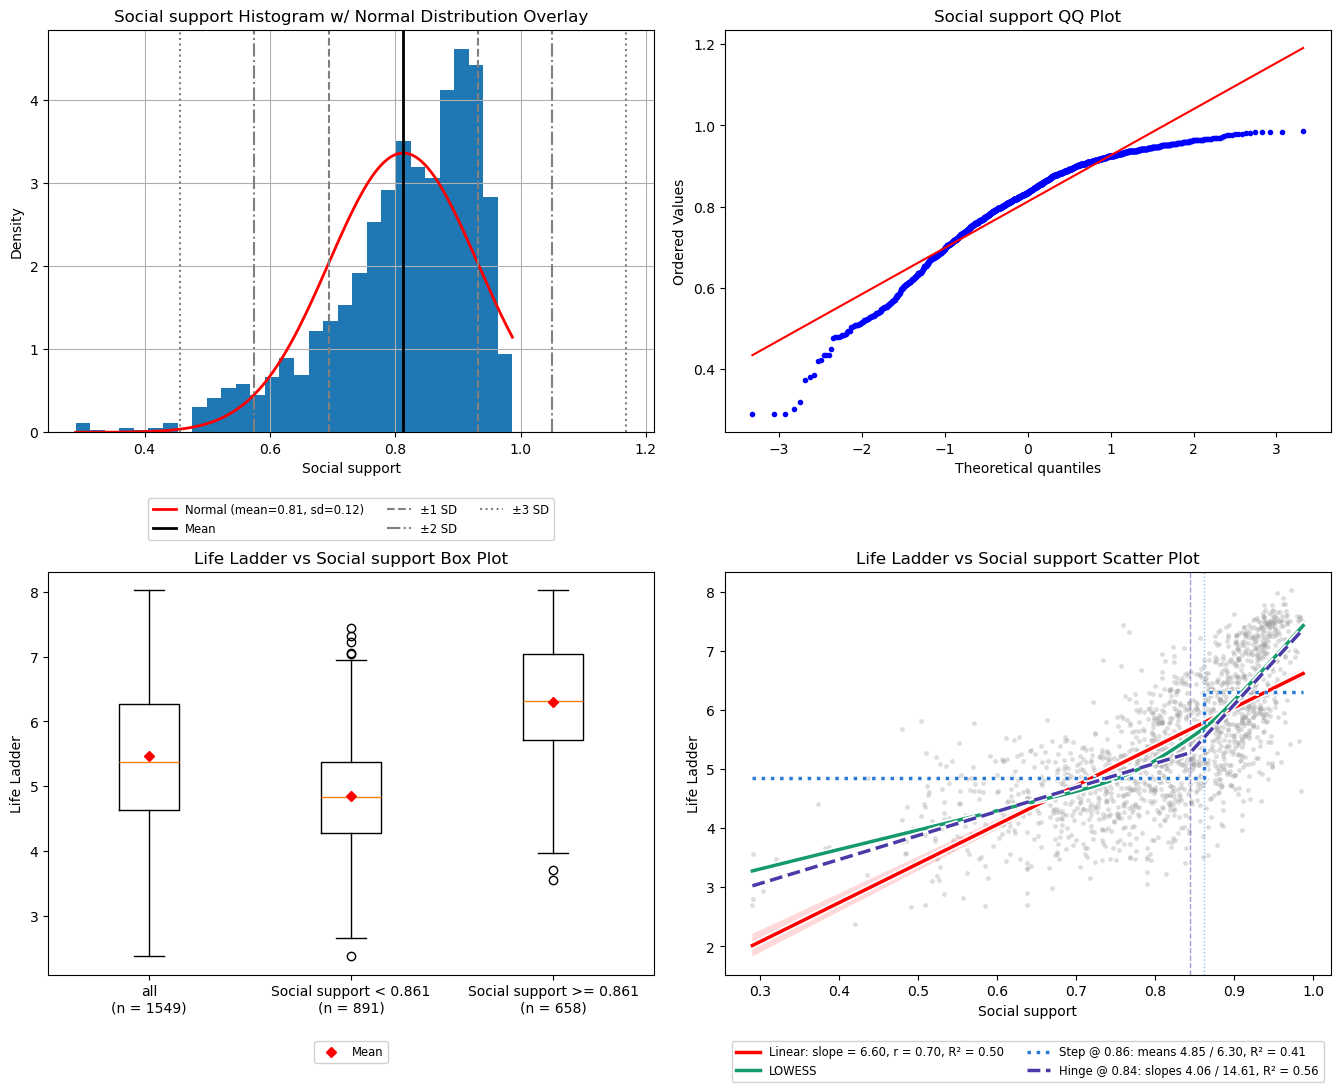

In [8]:
PLOTTING.single_feature_plots(df=train_df, feature=COLUMNS['SS']['col'], target=TARGET, threshold="auto");

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **Highly left skewed (-1.138) and leptokurtic (1.298).** Half the values sit between the 25% and 75% values (0.753 and 0.905), just below the max of 0.987, with a tail down to 0.29. In the QQ plot the low end falls below the line and the top flattens near 0.98.
- **42 low outliers** below the 0.525 fence, and none above. In the scatter plot they follow the LOWESS curve, so they look like part of the trend rather than errors.
- **Strong positive relationship:** r = 0.704 (R² 0.50).
- **Shallow, then steep.** LOWESS is shallow below about 0.8 and steep above. The hinge at 0.84 changes the slope from 4.06 to 14.61 and lifts R² from 0.50 to 0.56.
- **The straight line misses in a pattern.** It sits below LOWESS at both ends (it underpredicts Life Ladder in the low tail and at the top) and above it in the middle.
- **Both sides of the hinge have plenty of rows.** The hinge at 0.84 is next to the median (0.835). So about half the rows are below the hinge, where the slope is shallow, and about half are above it, where the slope is steep.

#### Special Treatment

Candidates, ranked by expected benefit:

1. **Raw value plus a hinge term:** `[x, max(0, x - 0.84)]`. It matches the two slopes directly, and both sides of the hinge have plenty of rows to fit.
2. **A transform that stretches the top end:** Yeo-Johnson first, logit second. One column and no threshold, and it reduces the skew and straightens the relationship in the same step.

- **Outliers:** keep the 42 low outliers. Clipping at the 0.525 fence is at most a small extra to test on top of 1 or 2.
- **Avoid replacing Social support with a step indicator.** A step indicator reproduces the step fit in the scatter plot: one Life Ladder level below 0.86 and another at or above it.
  - **It fits worse.** The step R² is 0.41, against 0.50 for the straight line and 0.56 for the hinge.
  - **It ignores the slopes on both sides of the hinge.** Every row on the same side of 0.86 gets the same prediction, whatever its value.
- **Avoid a hinge term without the raw value.** The slope below the hinge (4.06) is not flat, so the raw column has to stay.
- **Avoid log.** It stretches the low end, which is the wrong end.

## Generosity

In [9]:
STATISTICS.statistics_df(series=train_df[COLUMNS['G']['col']], target=train_df[TARGET])

,Generosity
count,1488.0
missing,71
% missing,4.554
mean,0.0
std,0.163
min,-0.335
25%,-0.113
50%,-0.025
75%,0.091
max,0.698


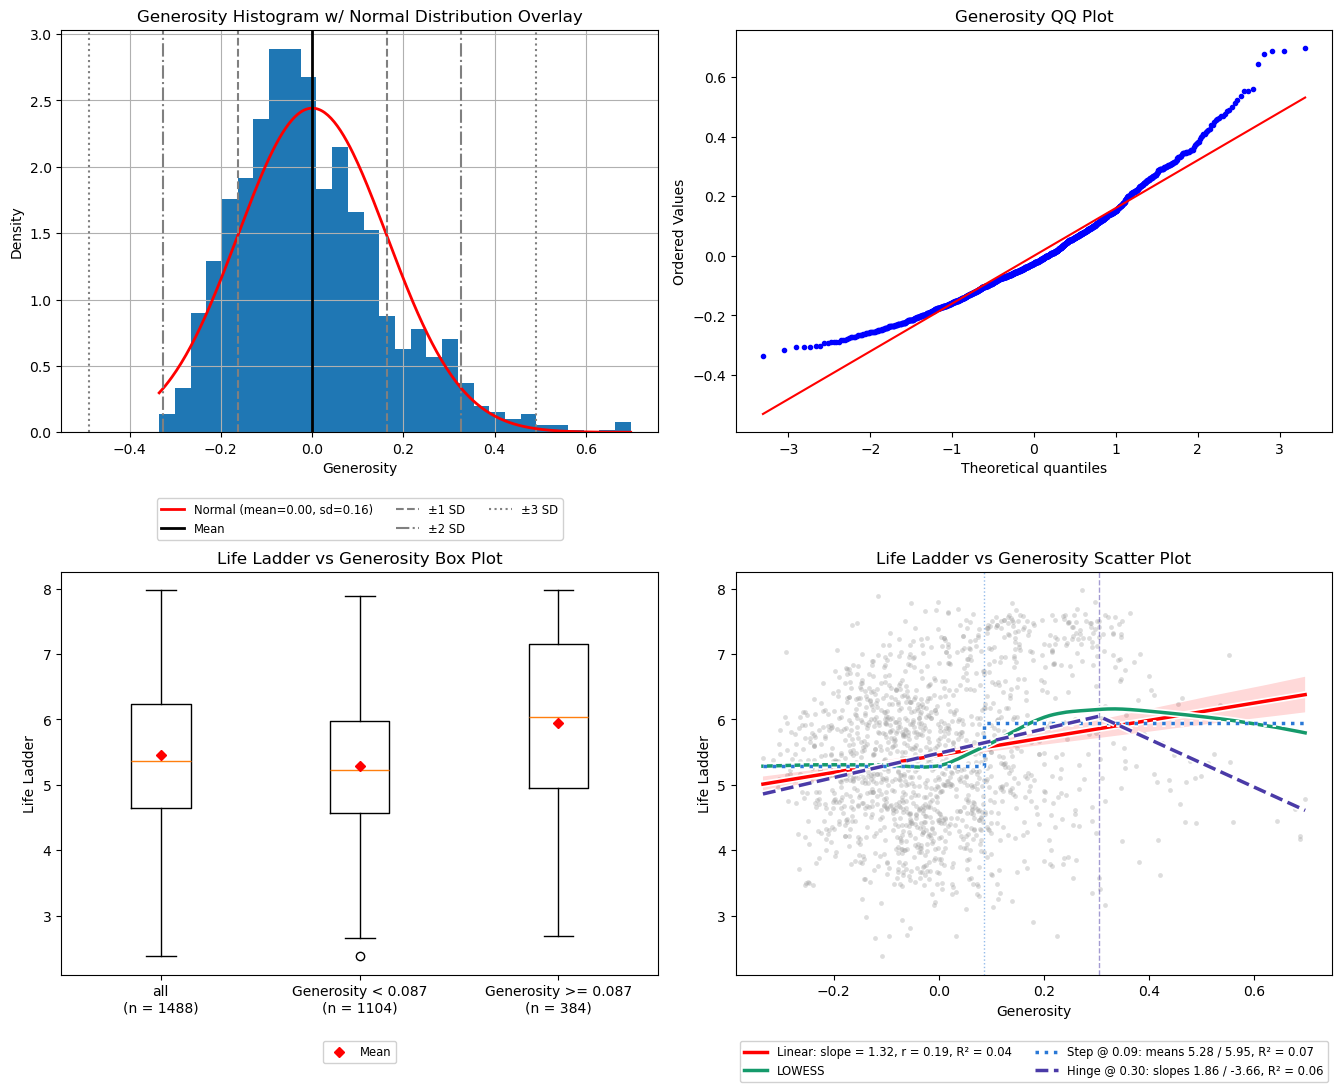

In [10]:
PLOTTING.single_feature_plots(df=train_df, feature=COLUMNS['G']['col'], target=TARGET, threshold="auto");

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **Centered on 0** (mean 0.0, median -0.025) and the only attribute with negative values (min -0.335, max 0.698).
- **Moderately right skewed (0.828), mesokurtic (0.945).** The histogram peaks just below 0 with a long right tail, which holds the **31 high outliers** above the 0.397 fence. There are none below.
- **Weakest relationship with Life Ladder:** r = 0.195 (R² 0.04).
- **What signal there is looks like a jump, not a slope.** LOWESS is flat below about 0.05, rises until about 0.3, then drifts down. The step at 0.09 (means 5.28 / 5.95) has the highest R² of the three fits: 0.07, vs 0.06 for the hinge and 0.04 for the straight line. In the box plot, the 384 rows at or above 0.087 have a median Life Ladder of about 6.0, vs about 5.2 for the 1,104 rows below.
- **The downturn rests on few rows.** The hinge at 0.30 flips the slope from 1.86 to -3.66, but only the thin right tail sits above 0.30, and LOWESS falls far less than the hinge does.
- **Second most missing values:** 71 (4.554%).

#### Special Treatment

Candidates, ranked by expected benefit:

1. **Drop the attribute.** It has the lowest R² of all (0.04), and its best fit only reaches 0.07, a value that is optimistic because the threshold was searched on the same rows. Dropping it also takes its 71 missing values out of the pipeline.
2. **If kept, replace the raw value with a step indicator** (1 when the value is at or above the step threshold of 0.087). One binary column carries more than the straight line does. A median fill (-0.025) would put the missing rows in the below group, which is the larger one (1,104 of 1,488 rows).
3. **Raw value plus a hinge term:** `[x, max(0, x - 0.30)]`. Lower priority, since the downturn it adds rests on the thin right tail.

- **Avoid log and Box-Cox.** They are not possible with negative values.
- **Avoid a skew fixing transform** (ex Yeo-Johnson). The signal is a jump in the middle of the range, and a smooth transform cannot produce a jump.
- **Avoid capping the 31 high outliers on its own.** LOWESS is nearly level across the top, so capping changes little.

## Healthy Life Expectancy at Birth

In [11]:
STATISTICS.statistics_df(series=train_df[COLUMNS['HLEAB']['col']], target=train_df[TARGET])

,Healthy life expectancy at birth
count,1522.0
missing,37
% missing,2.373
mean,63.332
std,7.478
min,32.3
25%,58.34
50%,65.18
75%,68.535
max,77.1


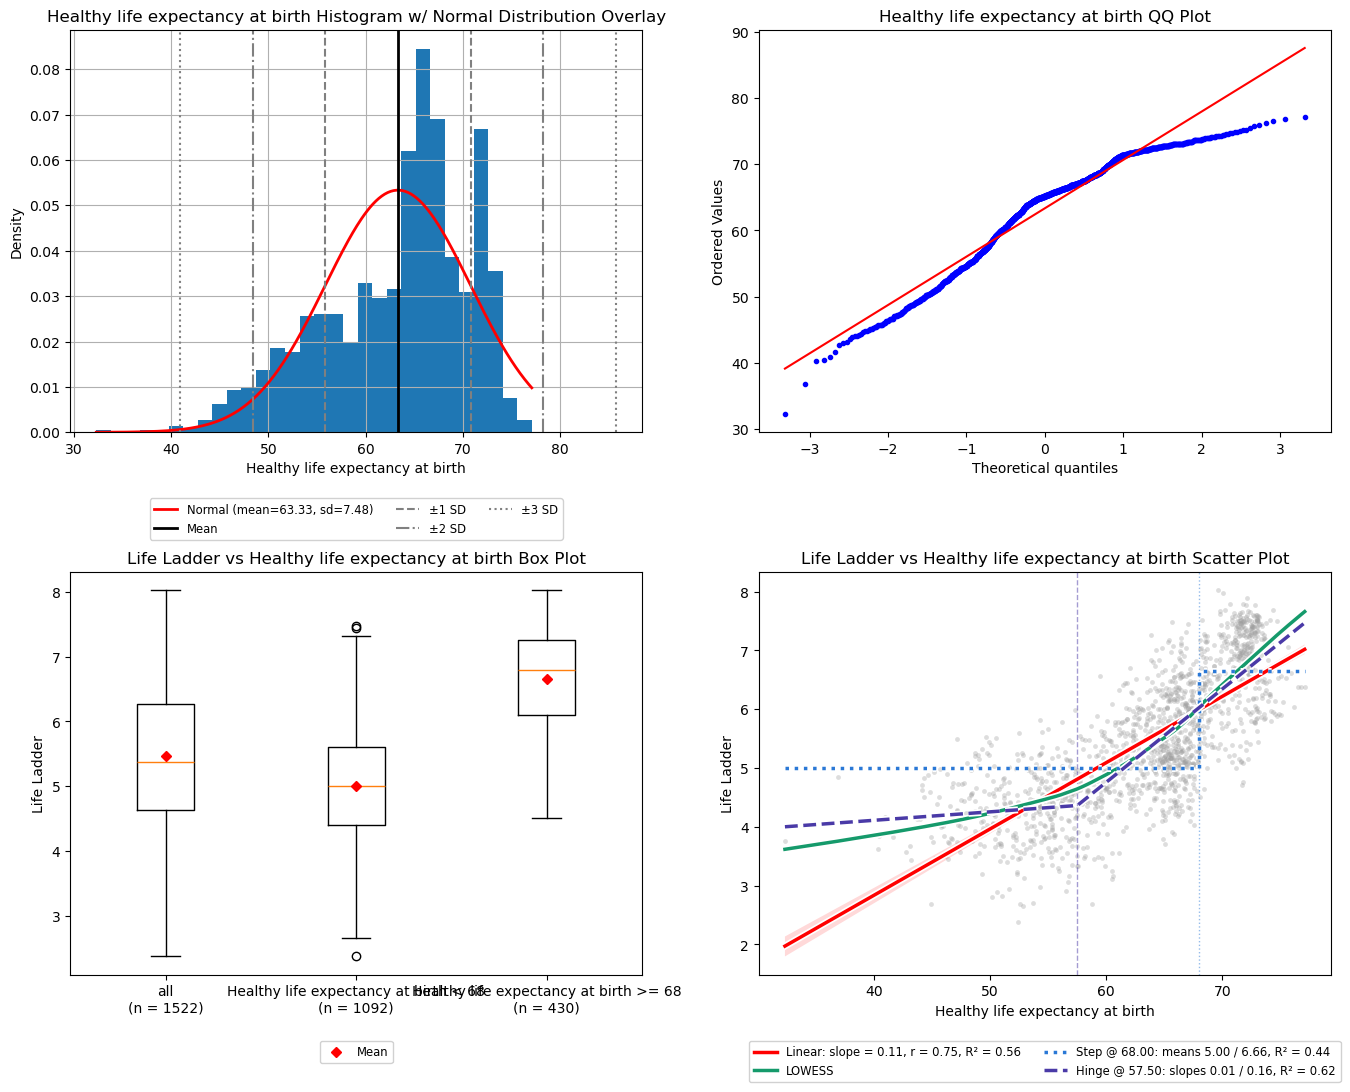

In [12]:
PLOTTING.single_feature_plots(df=train_df, feature=COLUMNS['HLEAB']['col'], target=TARGET, threshold="auto");

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **Moderately left skewed (-0.723), mesokurtic (-0.093).** The histogram has a broad lower shoulder (about 45 to 62) and a tall peak (about 64 to 74). In the QQ plot the top flattens around 74 to 77.
- **7 low outliers** below the 43.048 fence (min 32.3), and none above.
- **Strong positive relationship:** r = 0.751 (R² 0.56).
- **Flat, then steep.** LOWESS is shallow below about 57 and steep above. The hinge at 57.5 has slopes of 0.01 then 0.16 and lifts R² from 0.56 to 0.62, so below about 57.5 this attribute says almost nothing about Life Ladder.
- **The straight line pays for the flat part.** At the low end it predicts a Life Ladder of about 2 where LOWESS is at about 3.6, and at the top it sits below LOWESS. The hinge at 57.5 is just below the 25% value (58.34). So fewer than a quarter of the rows are below the hinge, where the slope is flat, and the rest are above it, where the slope is steep.
- **A step alone is not enough.** The step at 68 (means 5.00 / 6.66) reaches R² 0.44, below the linear R² of 0.56.
- **Largest scale of all the attributes:** values run from 32.3 to 77.1 with a std of 7.478, while every attribute other than Log GDP per capita has a std under 0.2.

#### Special Treatment

Candidates, ranked by expected benefit:

1. **Replace the raw value with a hinge term alone:** `max(0, x - 57.5)`. One column that is flat below the hinge and has one slope above it. The slope below the hinge is 0.01, so leaving the raw column out loses almost nothing.
2. **Raw value plus the same hinge term:** `[x, max(0, x - 57.5)]`. The same shape with a spare slope below the hinge, at the cost of an extra column.
3. **A transform that stretches the top end:** Yeo-Johnson first, a squared term second. No threshold needed, but a smooth curve cannot go fully flat below 57.5.

- **Scaling:** standardize it. Left as it is, it would dominate the smaller scale attributes in gradient descent and in any penalty.
- **Avoid log.** It compresses the steep top end and stretches the flat low end.
- **Avoid replacing Healthy life expectancy with a step indicator.** A step indicator reproduces the step fit in the scatter plot: one Life Ladder level below 68 and another at or above it.
  - **It fits worse.** The step R² is 0.44, against 0.56 for the straight line and 0.62 for the hinge.
  - **It ignores the rise above the hinge.** Every row on the same side of 68 gets the same prediction, whatever its value.
- **Avoid clipping the 7 low outliers.** With a hinge term the low end is already flat, so they have no pull on the fit.

## Negative Affect

In [13]:
STATISTICS.statistics_df(series=train_df[COLUMNS['NA']['col']], target=train_df[TARGET])

,Negative affect
count,1545.0
missing,14
% missing,0.898
mean,0.268
std,0.084
min,0.083
25%,0.206
50%,0.258
75%,0.319
max,0.705


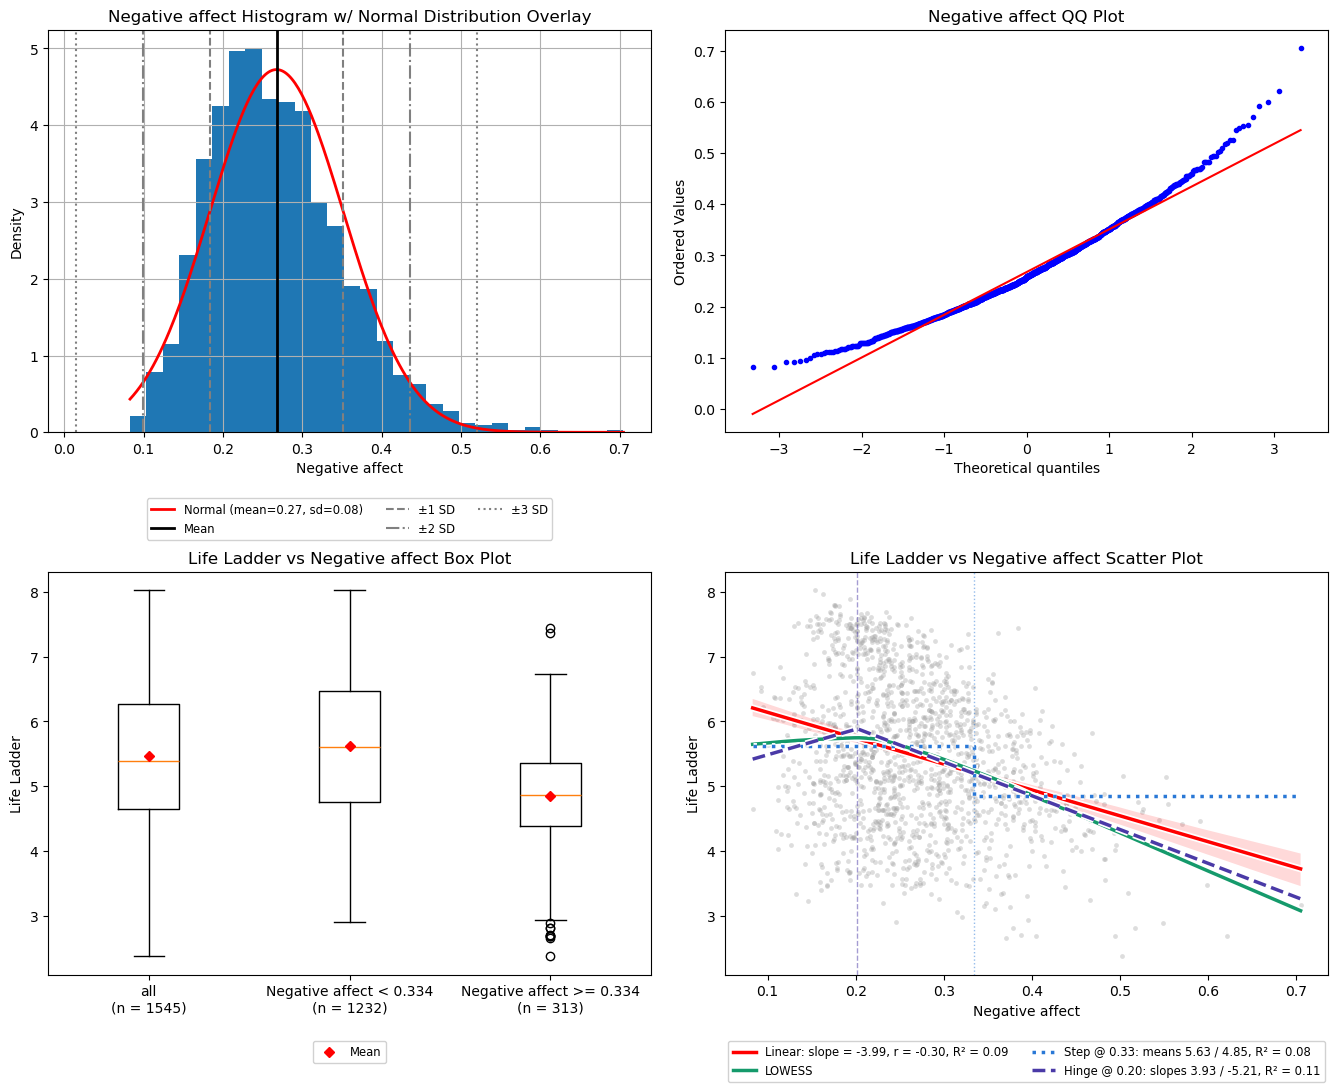

In [14]:
PLOTTING.single_feature_plots(df=train_df, feature=COLUMNS['NA']['col'], target=TARGET, threshold="auto");

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **Moderately right skewed (0.696), mesokurtic (0.801).** Values bunch at the low end (min 0.083) with a long right tail up to 0.705, which holds the **20 high outliers** above the 0.489 fence. There are none below.
- **Weak negative relationship:** r = -0.302 (R² 0.09). Only Generosity is weaker.
- **Only matters once it is high.** LOWESS is flat, even slightly rising, up to about 0.2, then falls. The hinge at 0.20 flips the slope from 3.93 to -5.21 (R² 0.11 vs 0.09).
- **Most rows are on the falling side.** The hinge at 0.20 is just below the 25% value (0.206). So about three quarters of the rows are above the hinge, where Life Ladder falls, and about a quarter are below it, where Life Ladder is flat or slightly rising.
- **A step alone does not capture it.** The step at 0.33 (means 5.63 / 4.85) reaches R² 0.08, below the linear R² of 0.09.
- **The high outliers sit in the range that carries the signal,** at the bottom of the falling part of the curve.

#### Special Treatment

Candidates, ranked by expected benefit:

1. **Drop the attribute.** Even its best fit explains little (R² 0.11), and that value is optimistic because the threshold was searched on the same rows.
2. **If kept, replace the raw value with a hinge term alone:** `max(0, x - 0.20)`. Flat below the hinge and one falling slope above it. The rising slope below the hinge (3.93) covers only about a quarter of the rows, and LOWESS shows that part as nearly flat.

- **Avoid log and Yeo-Johnson.** Fixing the right skew compresses the high tail, which is the part that carries the signal.
- **Avoid clipping the 20 high outliers,** for the same reason.
- **Avoid replacing Negative affect with a step indicator.** A step indicator reproduces the step fit in the scatter plot: one Life Ladder level below 0.33 and another at or above it.
  - **It fits worse.** The step R² is 0.08, against 0.09 for the straight line and 0.11 for the hinge.
  - **It ignores the fall above the hinge.** Every row on the same side of 0.33 gets the same prediction, whatever its value.

## Freedom to Make Life Choices

In [15]:
STATISTICS.statistics_df(series=train_df[COLUMNS['FTMLC']['col']], target=train_df[TARGET])

,Freedom to make life choices
count,1537.0
missing,22
% missing,1.411
mean,0.742
std,0.142
min,0.26
25%,0.646
50%,0.763
75%,0.855
max,0.985


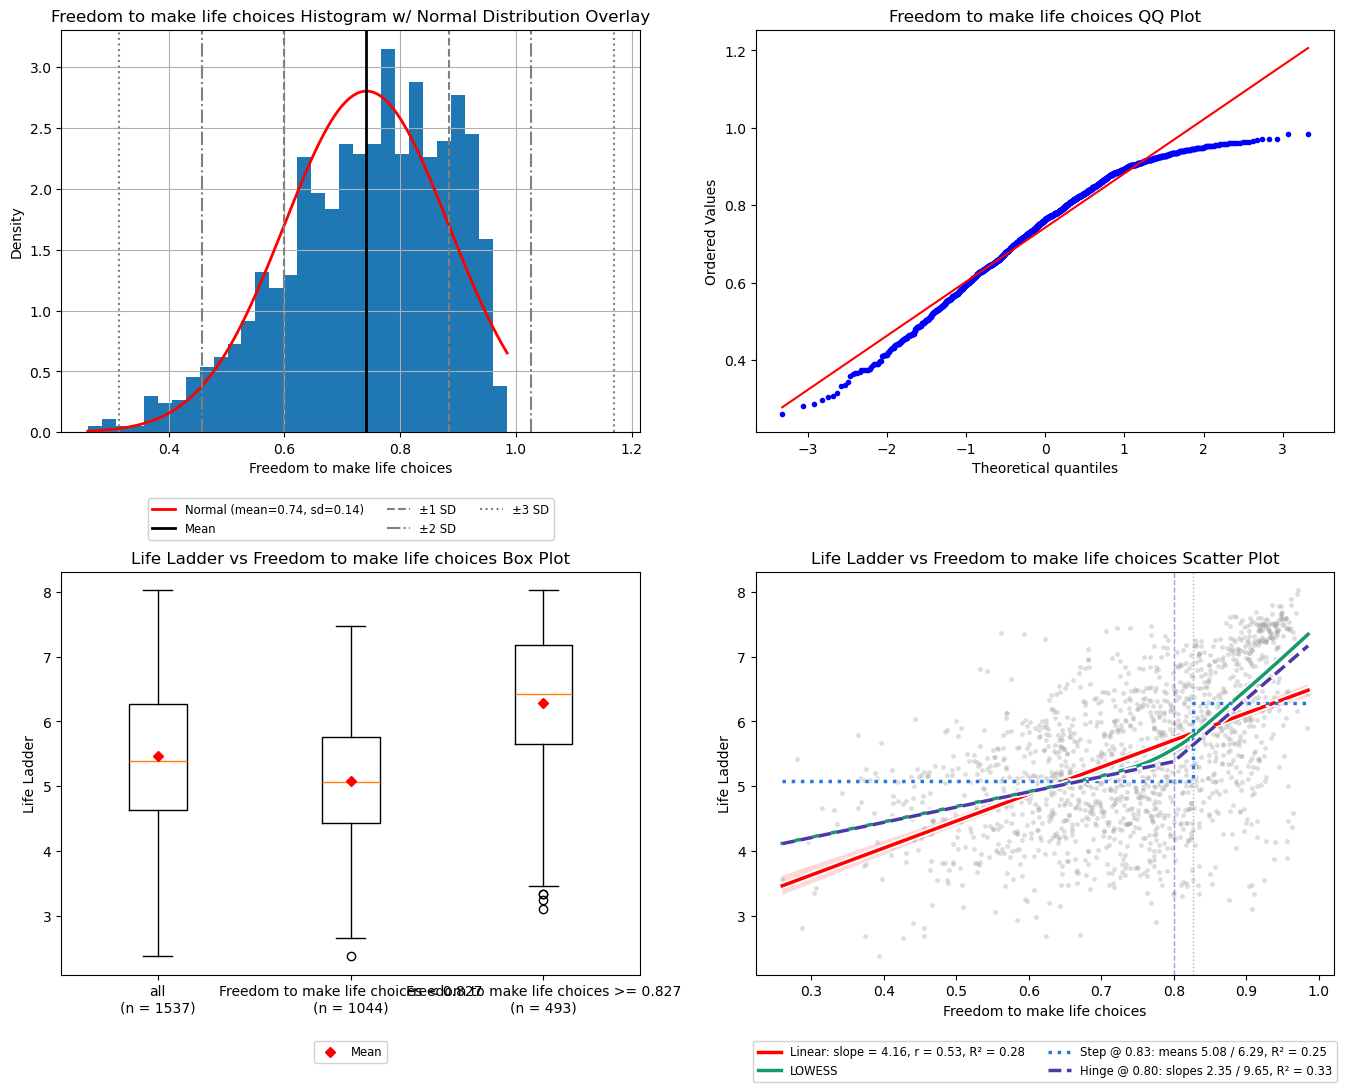

In [16]:
PLOTTING.single_feature_plots(df=train_df, feature=COLUMNS['FTMLC']['col'], target=TARGET, threshold="auto");

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **Moderately left skewed (-0.606), mesokurtic (-0.158).** Values crowd from about 0.85 up to the max of 0.985, and the QQ plot flattens at the top.
- **8 low outliers** below the 0.333 fence, and none above. They sit around the LOWESS curve.
- **Moderate positive relationship:** r = 0.53 (R² 0.28).
- **Shallow, then steep, but never flat.** LOWESS is shallow below about 0.8 and steep above. The hinge at 0.80 changes the slope from 2.35 to 9.65 and lifts R² from 0.28 to 0.33. The slope below the hinge (2.35) is not close to 0, so the low side still carries signal.
- **The straight line misses in a pattern.** It sits below LOWESS at both ends and above it in the middle.
- **A step alone is not enough.** The step at 0.83 (means 5.08 / 6.29) reaches R² 0.25, below the linear R² of 0.28. In the box plot, the 493 rows at or above 0.827 have a median Life Ladder of about 6.4, vs about 5.1 for the 1,044 rows below.

#### Special Treatment

Candidates, ranked by expected benefit:

1. **Raw value plus a hinge term:** `[x, max(0, x - 0.80)]`. It keeps the slope below the hinge and adds the steeper one above it.
2. **A transform that stretches only the top end:** `-log(1 - x)` first, logit second. One column and no threshold. Logit also stretches the low end, where nothing needs straightening.
3. **A squared term or Yeo-Johnson.** Both curve the right way, with a gentler change in slope than the hinge.
4. **Raw value alone.** The gain on offer is moderate (R² 0.28 to 0.33), so the raw column is the fallback if the extra term does not earn its place.

- **Avoid a hinge term without the raw value.** It would throw away the 2.35 slope below the hinge.
- **Avoid replacing Freedom with a step indicator.** A step indicator reproduces the step fit in the scatter plot: one Life Ladder level below 0.83 and another at or above it.
  - **It fits worse.** The step R² is 0.25, against 0.28 for the straight line and 0.33 for the hinge.
  - **It ignores the slopes on both sides of the hinge.** Every row on the same side of 0.83 gets the same prediction, whatever its value.
- **Avoid log.** It stretches the low end, which is the wrong end.
- **Outliers:** leave the 8 low outliers in. They are few and follow the trend.

## Positive Affect

In [17]:
STATISTICS.statistics_df(series=train_df[COLUMNS['PA']['col']], target=train_df[TARGET])

,Positive affect
count,1542.0
missing,17
% missing,1.09
mean,0.709
std,0.108
min,0.322
25%,0.623
50%,0.721
75%,0.798
max,0.944


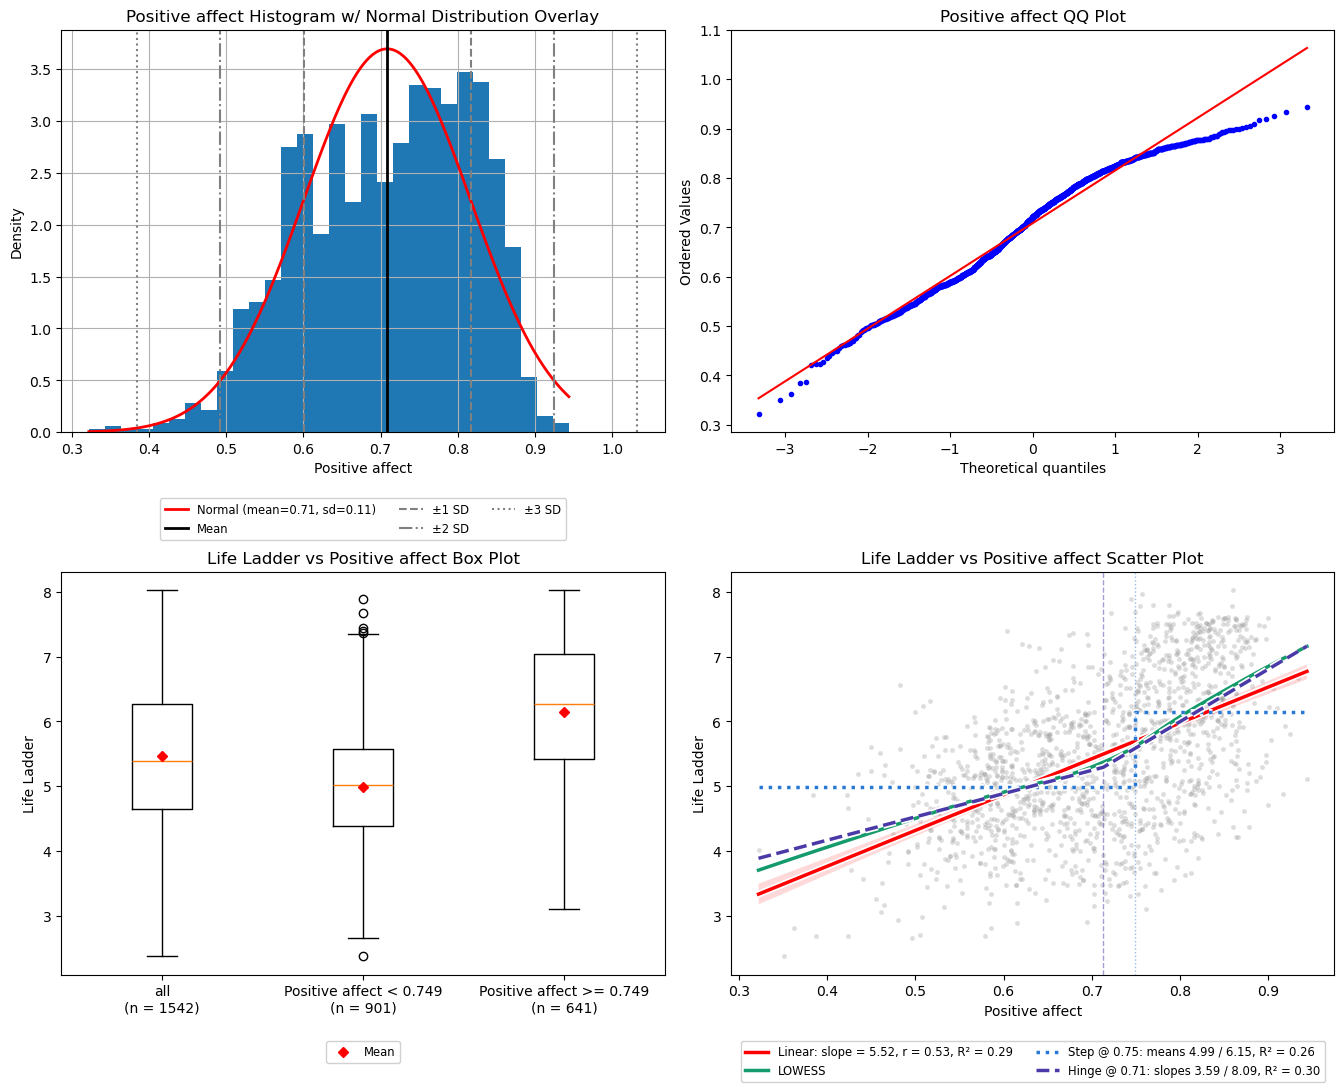

In [18]:
PLOTTING.single_feature_plots(df=train_df, feature=COLUMNS['PA']['col'], target=TARGET, threshold="auto");

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **Roughly symmetric (-0.348), mesokurtic (-0.607).** The histogram is broad and flat topped, with a possible second peak near 0.8, and the QQ plot stays close to the line.
- **Only 2 low outliers** below the 0.36 fence, and none above.
- **Moderate positive relationship:** r = 0.535 (R² 0.29).
- **Close to linear.** LOWESS tracks the straight line and steepens slightly above about 0.71. The hinge there (slopes 3.59 / 8.09) only lifts R² from 0.29 to 0.30, a gain of about the same size as the optimism in a hinge fit.
- **A step alone is not enough.** The step at 0.75 (means 4.99 / 6.15) reaches R² 0.26, below the linear R² of 0.29. In the box plot, the 641 rows at or above 0.749 have a median Life Ladder of about 6.3, vs about 5.0 for the 901 rows below.

#### Special Treatment

Candidates, ranked by expected benefit:

1. **Raw value alone.** This is the cleanest attribute: no skew to fix, almost no outliers, and a relationship that is already close to a straight line.
2. **Raw value plus one term for the rise between about 0.71 and 0.75:** a step indicator (1 when the value is at or above the step threshold of 0.749) or a hinge term (`max(0, x - 0.71)`). The expected gain is small, so keep the extra column only if it earns its place.
3. **A squared term.** It fits the mild upward curve, with the smallest expected gain of the three.

- **Avoid skew fixing transforms.** The distribution is already roughly symmetric.
- **Avoid transforms that stretch the top end** (ex `-log(1 - x)`, logit). The values are not crowded against the top (max 0.944).
- **Avoid replacing Positive affect with a step indicator.** A step indicator reproduces the step fit in the scatter plot: one Life Ladder level below 0.75 and another at or above it.
  - **It fits worse.** The step R² is 0.26, against 0.29 for the straight line and 0.30 for the hinge.
  - **It ignores the steady rise.** Every row on the same side of 0.75 gets the same prediction, whatever its value.

## Log GDP per Capita

In [19]:
STATISTICS.statistics_df(series=train_df[COLUMNS['LGDP']['col']], target=train_df[TARGET])

,Log GDP per capita
count,1533.0
missing,26
% missing,1.668
mean,9.363
std,1.16
min,6.635
25%,8.46
50%,9.456
75%,10.332
max,11.648


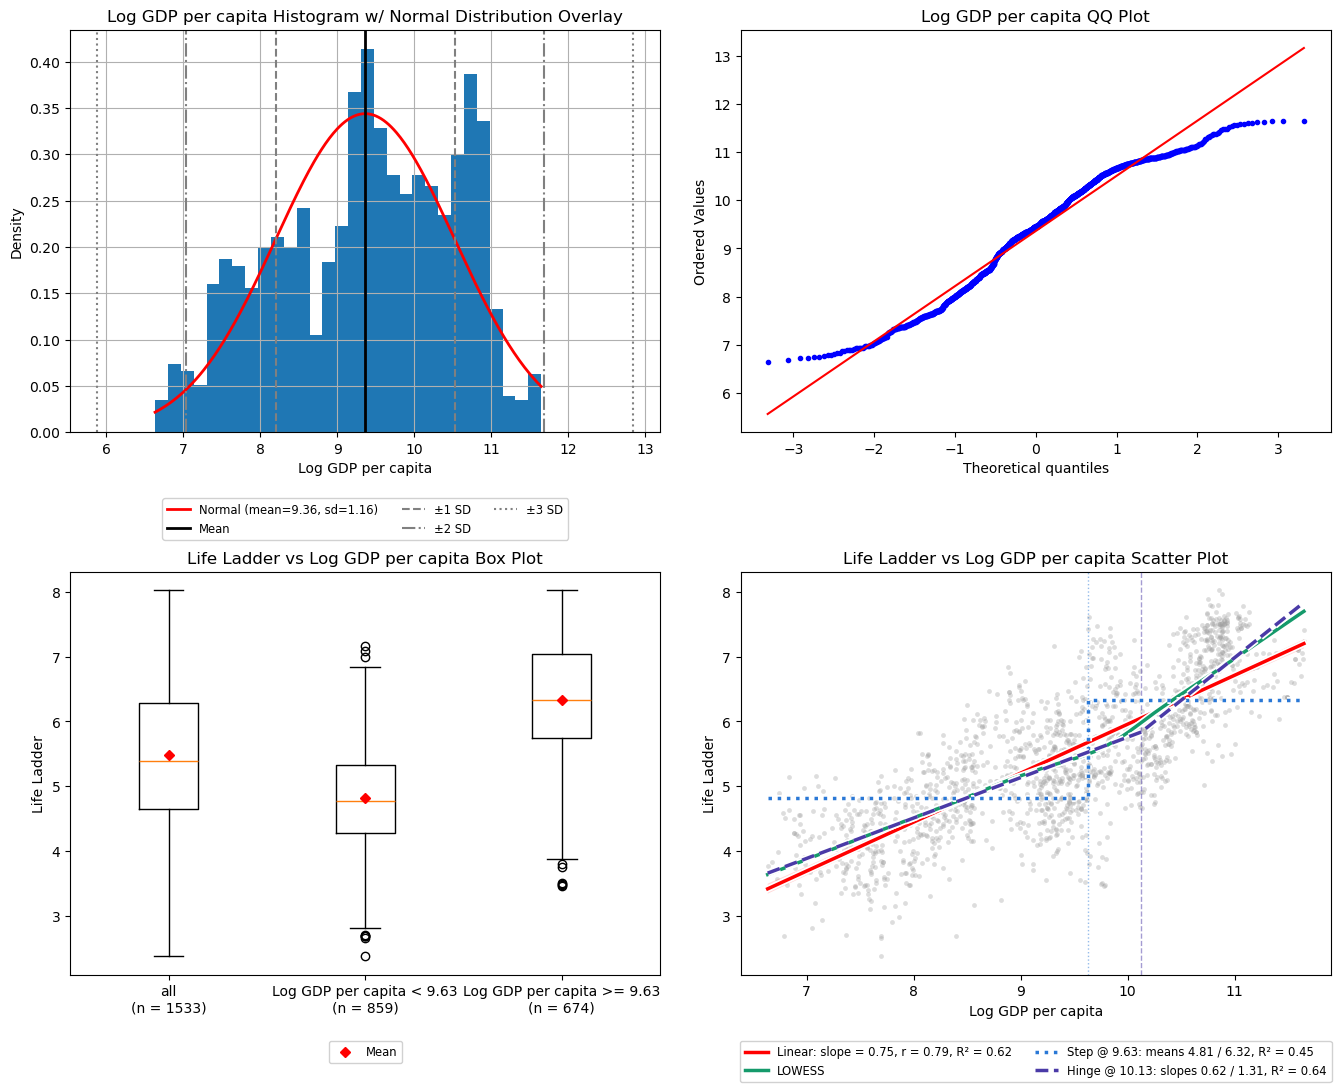

In [20]:
PLOTTING.single_feature_plots(df=train_df, feature=COLUMNS['LGDP']['col'], target=TARGET, threshold="auto");

### Notes / Observations

#### Noticeable Traits / Key Attributes

- **Already log transformed,** per the column name.
- **Roughly symmetric (-0.292), mesokurtic (-0.858).** The histogram is broad with several peaks (about 7.5, 9.3 and 10.8). In the QQ plot both ends turn back toward the middle (short tails), since the range is compact (6.635 to 11.648).
- **No outliers** on either side.
- **Strongest relationship with Life Ladder:** r = 0.787 (R² 0.62).
- **Linear at first glance, but the slope doubles at the top.** LOWESS tracks the straight line up to about 10, then steepens. The hinge at 10.13 changes the slope from 0.62 to 1.31 and lifts R² from 0.62 to 0.64. The hinge is just below the 75% value (10.332). So a little more than a quarter of the rows are above the hinge, where the slope is steeper, and the rest are below it.
- **The top end is where the straight line misses.** Above about 10.4 a dense cluster of rows with a Life Ladder of about 7 to 8 sits above the red line. At the very top (above about 11.2) the points appear to fall back below the hinge line, so one hinge may not describe the whole top end.
- **A step alone is not enough.** The step at 9.63 (means 4.81 / 6.32) reaches R² 0.45, well below the linear R² of 0.62.

#### Special Treatment

Candidates, ranked by expected benefit:

1. **Raw value plus one or two hinge terms above 10.** One hinge term, `max(0, x - 10.13)`, is the minimum. A second hinge term closer to 11 is worth testing, since the top end does not follow a single slope.
2. **Raw value plus a 0 / 1 indicator for the high cluster** (1 when the value is at or above about 10.4). This is not the step indicator: it sits where the cluster starts, not at the step threshold of 9.63.

- **Scaling:** standardize it along with the others. Its std (1.16) is well above the six attributes with a std under 0.2.
- **Avoid logging it again.** It is already logged and roughly symmetric, and another log would compress the top end, which is where the slope steepens.
- **Avoid leaving it raw just because r is the highest.** The slope doubles above the hinge, and a straight line cannot follow that.
- **Avoid replacing Log GDP per capita with a step indicator.** A step indicator reproduces the step fit in the scatter plot: one Life Ladder level below 9.63 and another at or above it.
  - **It fits worse.** The step R² is 0.45, against 0.62 for the straight line and 0.64 for the hinge.
  - **It ignores the slopes on both sides of the hinge.** Every row on the same side of 9.63 gets the same prediction, whatever its value.